### Verify the Environment

In [1]:
import sys
print(sys.executable)

C:\Users\Istiak\miniconda3\envs\dl_projects\python.exe


### Step 1: Load One Batch

In [2]:
# Import libraries
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np

In [4]:
# JupyterLab runs this notebook from the notebooks folder
project_root = Path.cwd().parent
data_folder = project_root / "datasets" / "cifar-10-batches-py"
batch_path = data_folder / "data_batch_1"

print("Mian Project Root:", project_root)
print("Dataset fodler:", data_folder)
print("Batch path:", batch_path)
print("File exists:", batch_path.exists())

Mian Project Root: E:\9_Self_ML_DL_Foundations\vision-from-scratch
Dataset fodler: E:\9_Self_ML_DL_Foundations\vision-from-scratch\datasets\cifar-10-batches-py
Batch path: E:\9_Self_ML_DL_Foundations\vision-from-scratch\datasets\cifar-10-batches-py\data_batch_1
File exists: True


In [5]:
# "rb" means read binary
with open(batch_path, "rb") as file:
    batch = pickle.load(file, encoding="bytes")

print(type(batch))
print(batch.keys())

<class 'dict'>
dict_keys([b'batch_label', b'labels', b'data', b'filenames'])


### Step 2: Inspect the Images and Labels
*Expected result: Image shape (10000, 3072), dtype uint8, label shape (10000,), and pixel values between 0 and 255.*

In [6]:
raw_images = batch[b"data"]
labels = np.array(batch[b"labels"])

print("Image shape:", raw_images.shape)
print("Image dtype:", raw_images.dtype)
print("Minimum pixel:", raw_images.min())
print("Maximum pixel:", raw_images.max())
print("Label shape:", labels.shape)
print("First labels:", labels[:10])

Image shape: (10000, 3072)
Image dtype: uint8
Minimum pixel: 0
Maximum pixel: 255
Label shape: (10000,)
First labels: [6 9 9 4 1 1 2 7 8 3]


### Step 3: Read the Class Names

In [7]:
meta_path = data_folder / "batches.meta"

with open(meta_path, "rb") as file:
    meta = pickle.load(file, encoding="bytes")

class_names = []

for name in meta[b"label_names"]:
    class_names.append(name.decode("utf-8"))

print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### Step 4: Build One Image by Hand

Image shape: (32, 32, 3)
Class: frog


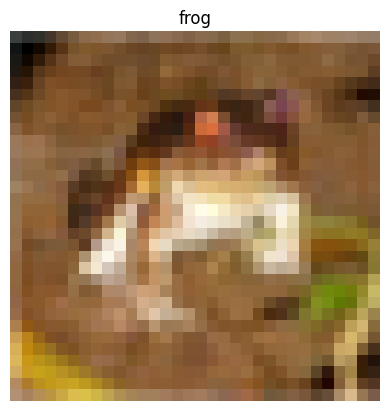

In [11]:
first_row = raw_images[0]

# Split the 3072 values into 3 color channels
red = first_row[0:1024]
green = first_row[1024:2048]
blue = first_row[2048:3072]

# Convert each channel into a 32 x 32 image
red_image = red.reshape(32, 32)
green_image = green.reshape(32, 32)
blue_image = blue.reshape(32, 32)

# Stack channels into one color image
image = np.stack([red_image, green_image, blue_image], axis=2)
# print(image)

print("Image shape:", image.shape)
print("Class:", class_names[labels[0]])

plt.imshow(image, interpolation="nearest")
plt.title(class_names[labels[0]])
plt.axis("off")
plt.show()

### Step 5: Reshape All Images at Once

In [12]:
number_of_images = raw_images.shape[0]

# Shape: (N, C, H, W)
images_nchw = raw_images.reshape(number_of_images, 3, 32, 32)

# Shape: (N, H, W, C)
images = images_nchw.transpose(0, 2, 3, 1)

print("NCHW shape:", images_nchw.shape)
print("NHWC shape:", images.shape)
print("Matches manual image:", np.array_equal(images[0], image))

NCHW shape: (10000, 3, 32, 32)
NHWC shape: (10000, 32, 32, 3)
Matches manual image: True


### Step 6: Check the Class Distribution
*Expected result: Each class has about 1,000 images. The counts may not be exactly equal within one training batch, but the five batches together contain exactly 5,000 images per class.*

airplane 1005
automobile 974
bird 1032
cat 1016
deer 999
dog 937
frog 1030
horse 1001
ship 1025
truck 981


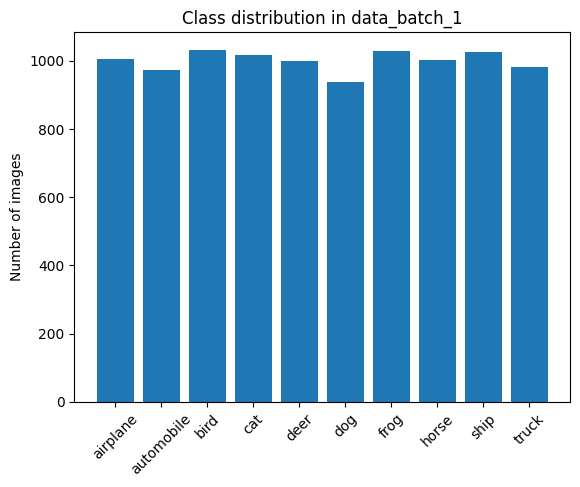

In [14]:
class_counts = np.bincount(labels, minlength=10)

for class_index in range(10):
    print(class_names[class_index], class_counts[class_index])

plt.bar(class_names, class_counts)
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.title("Class distribution in data_batch_1")
plt.show()

### Step 7: View One Image from Each Class

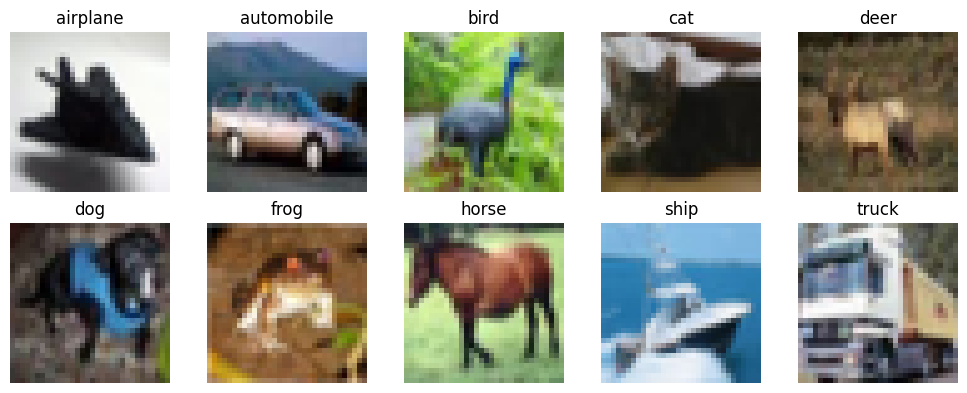

In [15]:
figure, axes = plt.subplots(2, 5, figsize=(10, 4))

for class_index in range(10):
    # Find every image of this class
    image_indices = np.where(labels == class_index)[0]

    # Use the first image from this class
    first_index = image_indices[0]

    # Find the position in the 2 x 5 grid
    row = class_index // 5
    column = class_index % 5

    axes[row, column].imshow(images[first_index], interpolation="nearest")
    axes[row, column].set_title(class_names[class_index])
    axes[row, column].axis("off")

plt.tight_layout()
plt.show()

## Part 2: Loading the Full Dataset

### Step 1: Load the Dataset

In [17]:
import matplotlib.pyplot as plt
import numpy as np

from scratchvision.data.cifar10 import DEFAULT_DATA_FOLDER
from scratchvision.data.cifar10 import load_batch
from scratchvision.data.cifar10 import load_cifar10
from scratchvision.data.cifar10 import load_class_names

X_train, y_train, X_test, y_test = load_cifar10()
class_names = load_class_names()

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test:", X_test.shape, X_test.dtype)
print("y_test:", y_test.shape, y_test.dtype)

X_train: (50000, 32, 32, 3) uint8
y_train: (50000,) int64
X_test: (10000, 32, 32, 3) uint8
y_test: (10000,) int64


### Step 2: Check Memory Usage

In [18]:
train_bytes = X_train.nbytes
train_megabytes = train_bytes / 1_000_000

print("Training pixel memory:", train_bytes, "bytes")
print("Training pixel memory:", train_megabytes, "MB")

Training pixel memory: 153600000 bytes
Training pixel memory: 153.6 MB


*This matches the hand calculation $50000 \times 32 \times 32 \times 3 = 153{,}600{,}000$ bytes.

এটা হাতের হিসাব $50000 \times 32 \times 32 \times 3 = 153{,}600{,}000$ bytes-এর সাথে মিলে যায়।*

### Step 3: Check the Class Balance

In [19]:
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

for class_index in range(10):
    print(class_names[class_index], train_counts[class_index], test_counts[class_index])

airplane 5000 1000
automobile 5000 1000
bird 5000 1000
cat 5000 1000
deer 5000 1000
dog 5000 1000
frog 5000 1000
horse 5000 1000
ship 5000 1000
truck 5000 1000


### Step 4: Verify the Index Formula

In [20]:
index = 23456

# Calculate the source batch and position
batch_number = index // 10000 + 1
position = index % 10000

print("Batch number:", batch_number)
print("Position:", position)

# Load the source batch directly
batch_path = DEFAULT_DATA_FOLDER / f"data_batch_{batch_number}"
batch_images, batch_labels = load_batch(batch_path)

# Compare both copies
same_image = np.array_equal(X_train[index], batch_images[position])
same_label = y_train[index] == batch_labels[position]

print("Same image:", same_image)
print("Same label:", same_label)

Batch number: 3
Position: 3456
Same image: True
Same label: True


### Step 5: Visualize Samples from Each Class

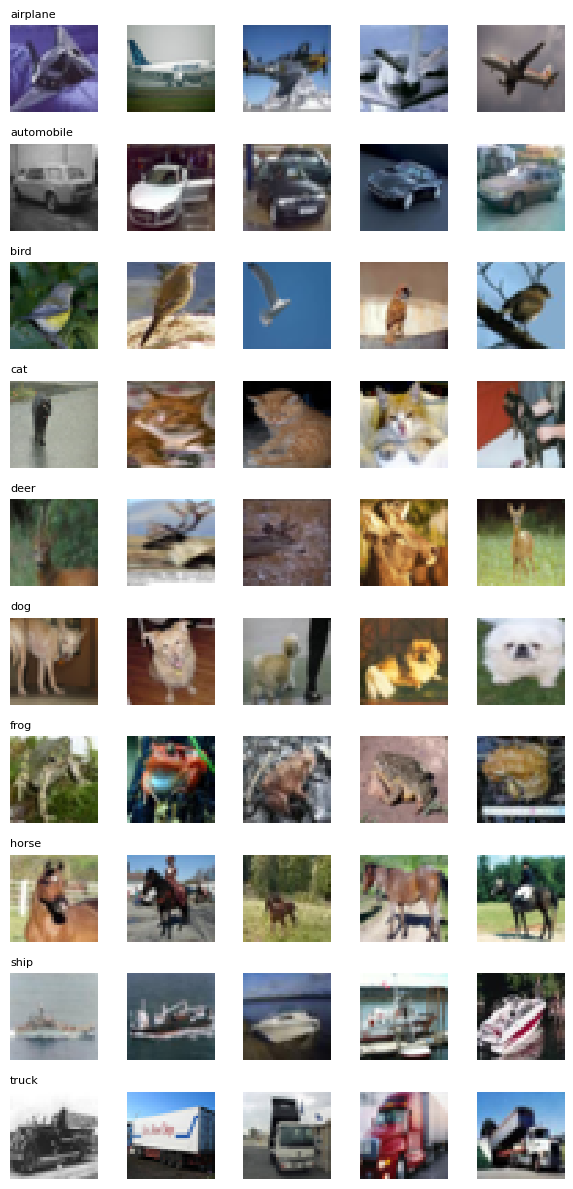

In [21]:
samples_per_class = 5
rng = np.random.default_rng(42)

figure, axes = plt.subplots(10, samples_per_class, figsize=(6, 12))

for class_index in range(10):
    # Find every training image of this class
    class_indices = np.where(y_train == class_index)[0]

    # Pick 5 different images
    chosen_indices = rng.choice(class_indices, size=samples_per_class, replace=False)

    for column in range(samples_per_class):
        image_index = chosen_indices[column]
        axes[class_index, column].imshow(X_train[image_index], interpolation="nearest")
        axes[class_index, column].axis("off")

    axes[class_index, 0].set_title(class_names[class_index], fontsize=8, loc="left")

plt.tight_layout()
plt.show()